# Telecom Customer Churn Prediction

## Objective
Build a machine-learning solution to:
- Understand customer attributes related to churn.
- Estimate the probability that a customer will churn.
- Classify customers as **Likely to Churn** or **Likely to Stay**.
- Evaluate the model using appropriate classification metrics.
- Analyze false positives and false negatives from a business perspective.
- Predict churn for unseen customer records.

**Dataset:** Telco Customer Churn


In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve
)

pd.set_option("display.max_columns", None)


In [ ]:
# 2. Load dataset
file_path = r"C:\Users\HP\OneDrive\Desktop\calibo\Datasets\Logistic Regression.csv"
df = pd.read_csv(file_path)

# TotalCharges contains some blank strings in the original dataset
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Dataset shape before cleaning:", df.shape)
display(df.head())


Dataset shape before cleaning: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 3. Data understanding
print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nChurn distribution:")
display(df["Churn"].value_counts())
display((df["Churn"].value_counts(normalize=True) * 100).round(2).to_frame("percentage"))


Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Missing values:


,missing_count
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0



Churn distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

,percentage
Churn,
No,73.46
Yes,26.54


In [4]:
# 4. Clean data
df = df.dropna(subset=["TotalCharges"]).copy()

# CustomerID is an identifier, not a predictive feature
# Churn is the target variable
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Shape after cleaning:", df.shape)
print("Churn rate:", round(y.mean() * 100, 2), "%")


Shape after cleaning: (7032, 21)
Churn rate: 26.58 %


## Relevant input features

Potentially useful features include:

- **Tenure:** newer customers may be more likely to leave.
- **Contract:** month-to-month customers often have less commitment.
- **MonthlyCharges / TotalCharges:** indicate customer spending and value.
- **InternetService:** may capture differences in service type.
- **TechSupport / OnlineSecurity:** service-support engagement can affect retention.
- **PaymentMethod:** payment friction and preferences may relate to churn.
- **PaperlessBilling:** may correlate with customer behavior.
- **SeniorCitizen, Partner, Dependents:** demographic/family context.
- **PhoneService and additional services:** service bundle information.

The model will automatically encode categorical variables and scale numerical variables.


/tmp/ipykernel_473/522131462.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([stay, churn], labels=["No", "Yes"])


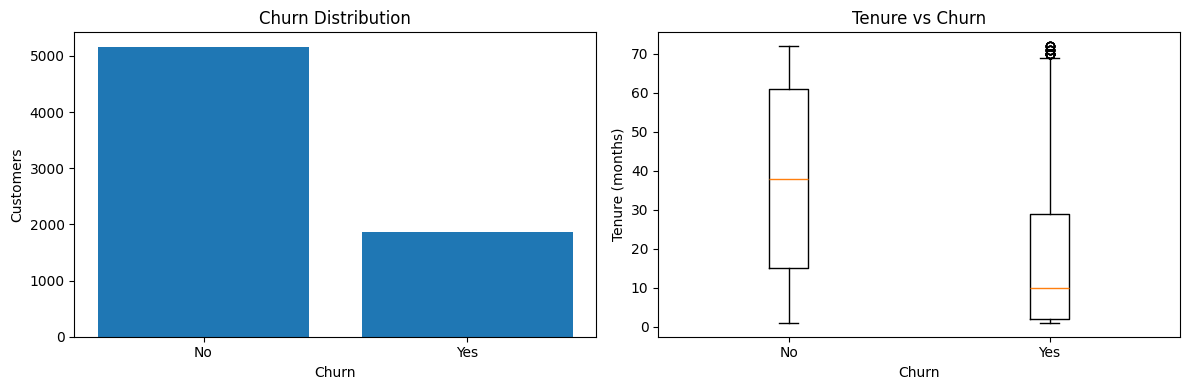

In [5]:
# 5. Quick exploratory analysis
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

churn_counts = df["Churn"].value_counts()
axes[0].bar(churn_counts.index, churn_counts.values)
axes[0].set_title("Churn Distribution")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Customers")

stay = df.loc[df["Churn"] == "No", "tenure"].dropna()
churn = df.loc[df["Churn"] == "Yes", "tenure"].dropna()
axes[1].boxplot([stay, churn], labels=["No", "Yes"])
axes[1].set_title("Tenure vs Churn")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Tenure (months)")

plt.tight_layout()
plt.show()


In [6]:
# 6. Prepare preprocessing pipeline
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [7]:
# 7. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


Training records: 5625
Testing records: 1407


In [8]:
# 8. Build Logistic Regression churn-probability model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

model.fit(X_train, y_train)

# Probability of churn
y_prob = model.predict_proba(X_test)[:, 1]

# Default classification threshold
threshold = 0.50
y_pred = (y_prob >= threshold).astype(int)

print("Model training completed.")


Model training completed.


In [9]:
# 9. Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Likely to Stay", "Likely to Churn"]
))


Accuracy : 0.7257
Precision: 0.4901
Recall   : 0.7968
F1 Score : 0.6069
ROC-AUC  : 0.8351

Classification Report:
                 precision    recall  f1-score   support

 Likely to Stay       0.90      0.70      0.79      1033
Likely to Churn       0.49      0.80      0.61       374

       accuracy                           0.73      1407
      macro avg       0.70      0.75      0.70      1407
   weighted avg       0.79      0.73      0.74      1407



True Negatives (correctly identified stay): 723
False Positives (non-churn misclassified as churn): 310
False Negatives (churn customers missed): 76
True Positives (correctly identified churn): 298


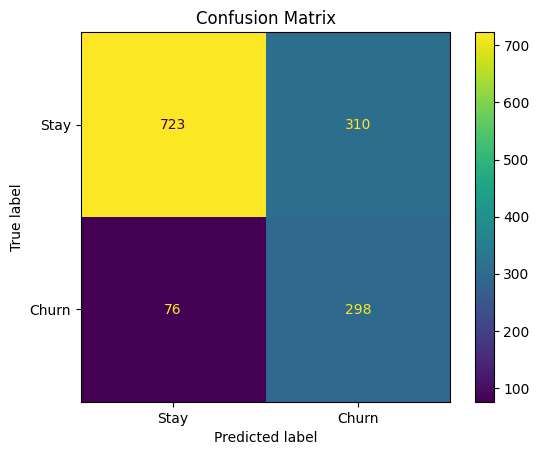

In [10]:
# 10. Confusion matrix
cm = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = cm.ravel()

print("True Negatives (correctly identified stay):", tn)
print("False Positives (non-churn misclassified as churn):", fp)
print("False Negatives (churn customers missed):", fn)
print("True Positives (correctly identified churn):", tp)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stay", "Churn"]
).plot()
plt.title("Confusion Matrix")
plt.show()


In [11]:
# 11. Answer the key business questions
print(f"How many churn customers were correctly identified? {tp}")
print(f"How many non-churn customers were misclassified? {fp}")
print(f"How many actual churners were missed? {fn}")


How many churn customers were correctly identified? 298
How many non-churn customers were misclassified? 310
How many actual churners were missed? 76


## Business interpretation

### False Positive: Loyal customer flagged as churn
The company may offer a discount or retention incentive to a customer who was actually going to stay. This creates an unnecessary retention cost.

### False Negative: Churning customer classified as stay
This is usually more costly because the company misses the opportunity to intervene and may lose recurring revenue plus incur acquisition costs to replace the customer.

### Which error matters more?
For a retention campaign, **false negatives are often more costly** than false positives. Therefore, the company should generally prioritize **high recall for churn**, while controlling the number of unnecessary offers.

The exact choice should be based on the financial value of a saved customer versus the cost of a retention offer.


In [12]:
# 12. Choose a lower threshold to prioritize churn recall
# This is an example; the business should select the threshold using actual retention costs.
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

rows = []
for t in thresholds:
    pred_t = (y_prob >= t).astype(int)
    rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t, zero_division=0),
        "F1": f1_score(y_test, pred_t, zero_division=0)
    })

threshold_df = pd.DataFrame(rows)
display(threshold_df.round(3))


,Threshold,Precision,Recall,F1
0,0.3,0.415,0.930,0.574
1,0.4,0.452,0.872,0.595
2,0.5,0.490,0.797,0.607
3,0.6,0.541,0.717,0.617
4,0.7,0.611,0.618,0.614


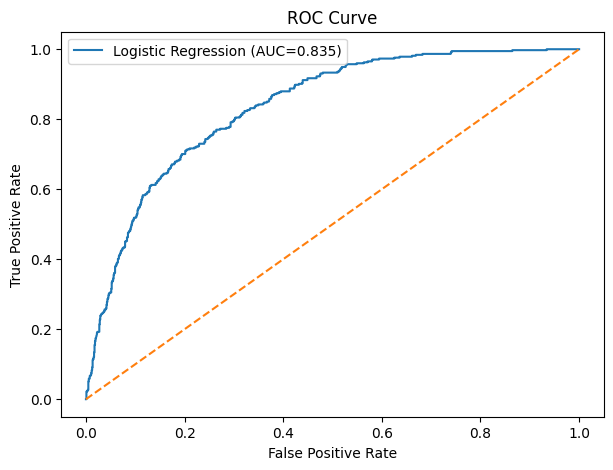

In [13]:
# 13. ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC={roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


In [14]:
# 14. Predict churn probability for unseen customer records
# Replace the example values below with new customer records.
# IMPORTANT: Do not include customerID or Churn in the input.

unseen_customers = pd.DataFrame([
    {
        "gender": "Female",
        "SeniorCitizen": 0,
        "Partner": "Yes",
        "Dependents": "No",
        "tenure": 2,
        "PhoneService": "Yes",
        "MultipleLines": "No",
        "InternetService": "Fiber optic",
        "OnlineSecurity": "No",
        "OnlineBackup": "No",
        "DeviceProtection": "No",
        "TechSupport": "No",
        "StreamingTV": "No",
        "StreamingMovies": "No",
        "Contract": "Month-to-month",
        "PaperlessBilling": "Yes",
        "PaymentMethod": "Electronic check",
        "MonthlyCharges": 80.0,
        "TotalCharges": 160.0
    }
])

unseen_prob = model.predict_proba(unseen_customers)[:, 1]
unseen_class = np.where(unseen_prob >= threshold, "Likely to Churn", "Likely to Stay")

prediction_result = unseen_customers.copy()
prediction_result["Churn_Probability"] = unseen_prob
prediction_result["Prediction"] = unseen_class

display(
    prediction_result[["tenure", "Contract", "MonthlyCharges",
                       "Churn_Probability", "Prediction"]]
)


,tenure,Contract,MonthlyCharges,Churn_Probability,Prediction
0,2,Month-to-month,80.0,0.821256,Likely to Churn


## Final conclusions

1. The model estimates an individual customer's probability of churn.
2. Customers can be classified using a probability threshold.
3. **Recall** is especially important for churn because missing a true churner can result in lost revenue.
4. **Precision** is also important because unnecessary retention offers cost money.
5. The confusion matrix separates correct predictions, false positives, and false negatives.
6. A practical improvement is to **tune the probability threshold using actual business costs** instead of automatically using 0.50.
7. Another improvement would be to test stronger models such as **Random Forest, Gradient Boosting, or XGBoost**, and compare them using cross-validation and ROC-AUC/PR-AUC.


In [15]:
# 15. Compact final result summary
summary = pd.DataFrame({
    "Metric": [
        "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC",
        "Correct churn identified (TP)",
        "Non-churn misclassified as churn (FP)",
        "Churn customers missed (FN)"
    ],
    "Value": [
        accuracy, precision, recall, f1, roc_auc, tp, fp, fn
    ]
})

display(summary.round(4))


,Metric,Value
0,Accuracy,0.7257
1,Precision,0.4901
2,Recall,0.7968
3,F1 Score,0.6069
4,ROC-AUC,0.8351
5,Correct churn identified (TP),298.0000
6,Non-churn misclassified as churn (FP),310.0000
7,Churn customers missed (FN),76.0000
